In [17]:
import pandas as pd
import matplotlib.pyplot as plt

In [18]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [19]:
network_traffic = pd.read_excel("network_traffic.xlsx")

network_traffic.head()

,timestamp,source_ip,destination_ip,protocol,length,flags,alert
0,2023-01-09 23:41:44,145.106.168.237,151.99.239.65,TCP,321,SYN,Phishing
1,2023-01-25 20:20:55,15.14.213.0,151.99.239.65,ICMP,632,SYN,NaN
2,2023-01-01 21:58:48,208.218.189.31,151.99.239.65,TCP,603,RST,NaN
3,2023-01-23 06:30:18,208.218.189.31,50.136.117.83,ICMP,541,SYN,NaN
4,2023-01-30 23:12:23,252.213.123.239,151.99.239.65,UDP,198,SYN-ACK,NaN


In [20]:
network_traffic.describe(include="all")

,timestamp,source_ip,destination_ip,protocol,length,flags,alert
count,2000,2000,2000,2000,2000.000000,2000,938
unique,NaN,636,6,3,NaN,4,4
top,NaN,208.218.189.31,151.99.239.65,UDP,NaN,SYN-ACK,Phishing
freq,NaN,194,1414,682,NaN,536,290
mean,2023-01-16 06:39:09.052000,NaN,NaN,NaN,772.020000,NaN,NaN
min,2023-01-01 00:36:35,NaN,NaN,NaN,40.000000,NaN,NaN
25%,2023-01-08 10:55:09.500000,NaN,NaN,NaN,414.500000,NaN,NaN
50%,2023-01-16 17:37:19.500000,NaN,NaN,NaN,762.000000,NaN,NaN
75%,2023-01-23 20:42:11.750000128,NaN,NaN,NaN,1156.250000,NaN,NaN
max,2023-01-30 23:14:57,NaN,NaN,NaN,1498.000000,NaN,NaN


In [21]:
network_traffic["timestamp"] = pd.to_datetime(
    network_traffic["timestamp"],
    format="%Y-%m-%d %H:%M:%S"
)

network_traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       2000 non-null   datetime64[ns]
 1   source_ip       2000 non-null   object        
 2   destination_ip  2000 non-null   object        
 3   protocol        2000 non-null   object        
 4   length          2000 non-null   int64         
 5   flags           2000 non-null   object        
 6   alert           938 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 109.5+ KB


In [22]:
network_traffic["source_ip"].value_counts().head(5)

source_ip
208.218.189.31     194
252.213.123.239    192
145.106.168.237    178
33.234.69.221      177
15.14.213.0        177
Name: count, dtype: int64

In [23]:
top_sources = (network_traffic
    .groupby("source_ip")
    .size()
    .reset_index(name="traffic_count")
    .sort_values("traffic_count", ascending=False)
    .head(5))

top_sources

,source_ip,traffic_count
334,208.218.189.31,194
455,252.213.123.239,192
151,145.106.168.237,178
489,33.234.69.221,177
163,15.14.213.0,177


In [24]:
network_traffic["destination_ip"].value_counts().head(5)

destination_ip
151.99.239.65      1414
169.210.202.187     136
153.18.211.92       116
50.136.117.83       115
2.212.88.236        113
Name: count, dtype: int64

**Analysis of Source and Destination IP Addresses**
The most active source IP was 208.218.189.31 with 194 records, while the most active destination IP was 151.99.239.65 with 1,414 records. The high amount of traffic directed toward one IP address could indicate unusual network activity. However, more investigation would be needed to determine whether the traffic is malicious.

In [25]:
network_traffic["protocol"].value_counts()

protocol
UDP     682
TCP     670
ICMP    648
Name: count, dtype: int64

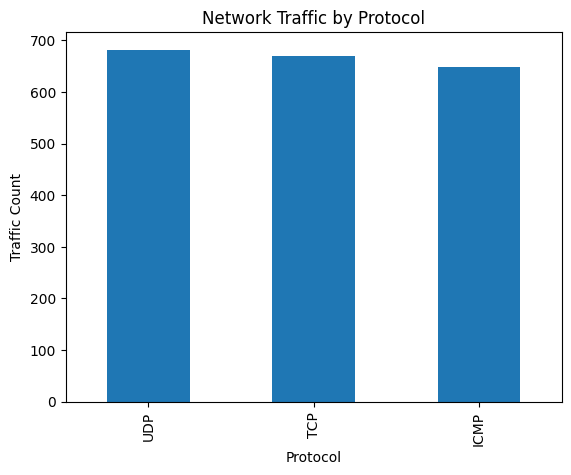

In [26]:
network_traffic["protocol"].value_counts().plot(kind="bar")

plt.title("Network Traffic by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Traffic Count")
plt.show()

**Protocol Analysis**
The dataset contains three protocols: TCP, UDP, and ICMP. UDP had the highest traffic count with 682 records, followed by TCP with 670 and ICMP with 648. The traffic was fairly evenly distributed across all three protocols. Although this does not necessarily indicate malicious activity, unusual protocol usage could be a sign of potential security threats.

In [27]:
network_traffic["date"] = network_traffic["timestamp"].dt.date

network_traffic.head()

,timestamp,source_ip,destination_ip,protocol,length,flags,alert,date
0,2023-01-09 23:41:44,145.106.168.237,151.99.239.65,TCP,321,SYN,Phishing,2023-01-09
1,2023-01-25 20:20:55,15.14.213.0,151.99.239.65,ICMP,632,SYN,NaN,2023-01-25
2,2023-01-01 21:58:48,208.218.189.31,151.99.239.65,TCP,603,RST,NaN,2023-01-01
3,2023-01-23 06:30:18,208.218.189.31,50.136.117.83,ICMP,541,SYN,NaN,2023-01-23
4,2023-01-30 23:12:23,252.213.123.239,151.99.239.65,UDP,198,SYN-ACK,NaN,2023-01-30


In [28]:
daily_volume = (network_traffic
    .groupby("date")
    .size()
    .reset_index(name="traffic_count"))

daily_volume

,date,traffic_count
0,2023-01-01,68
1,2023-01-02,72
2,2023-01-03,58
3,2023-01-04,74
4,2023-01-05,62
5,2023-01-06,68
6,2023-01-07,72
7,2023-01-08,66
8,2023-01-09,48
9,2023-01-10,50


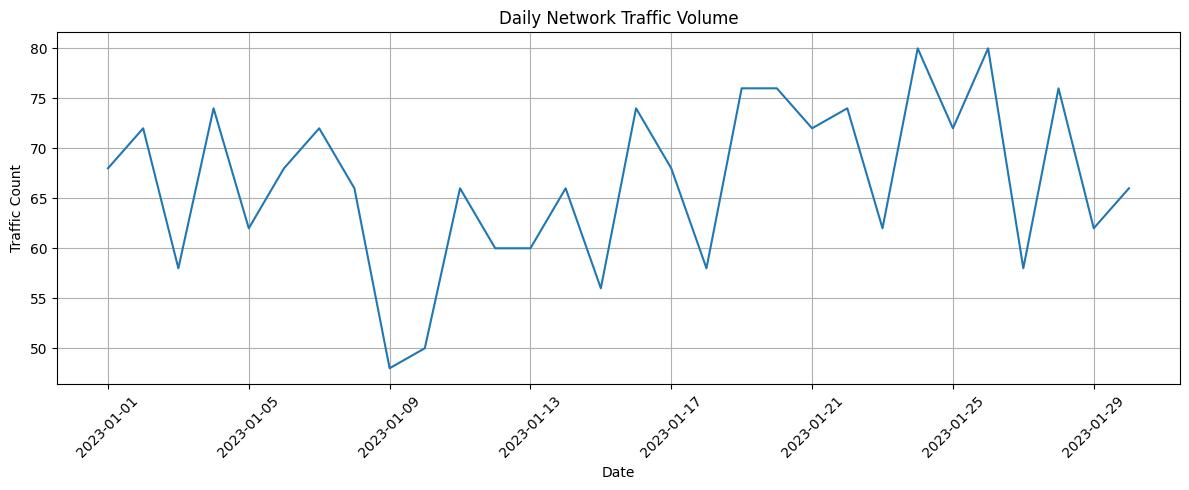

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(daily_volume["date"], daily_volume["traffic_count"])

plt.title("Daily Network Traffic Volume")
plt.xlabel("Date")
plt.ylabel("Traffic Count")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Daily Network Traffic Analysis**
The line graph shows how network traffic changed throughout January 2023. The highest traffic occurred on January 24 with 80 records, while the lowest occurred on January 9 with 48 records. These changes show that network activity varied throughout the month. Sudden increases in traffic could indicate suspicious activity and may require further investigation.

In [30]:
network_traffic["alert"].value_counts()

alert
Phishing             290
Malware              222
Data Exfiltration    220
DDoS                 206
Name: count, dtype: int64

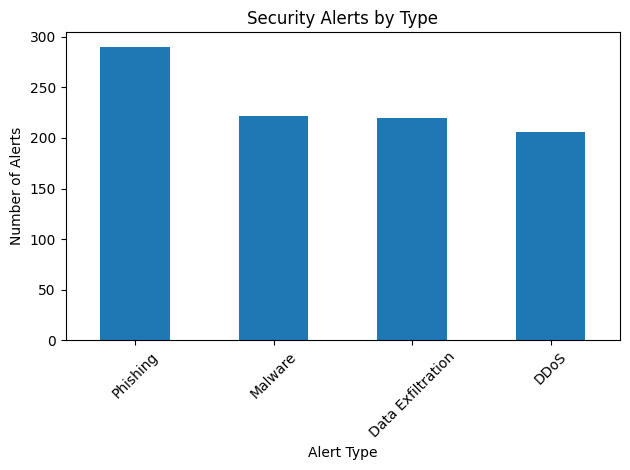

In [31]:
network_traffic["alert"].value_counts().plot(kind="bar")

plt.title("Security Alerts by Type")
plt.xlabel("Alert Type")
plt.ylabel("Number of Alerts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Mitigation Strategies**

The network traffic analysis identified four potential cybersecurity threats: phishing (290 alerts), malware (222 alerts), data exfiltration (220 alerts), and DDoS attacks (206 alerts).

**1. Phishing:** FinanceTech Inc. should use email filters and provide employee cybersecurity training. This would help employees recognize suspicious emails and avoid clicking harmful links.

**2. Malware:** The company should install antivirus software and regularly update its systems. This would help detect malicious software and prevent attackers from exploiting security weaknesses.

**3. Data Exfiltration:** FinanceTech Inc. should monitor unusual data transfers and limit access to sensitive information. Security tools can alert the cybersecurity team when suspicious transfers occur.

**4. DDoS Attacks:** The company should use firewalls, rate limiting, and DDoS protection services. These measures would help prevent excessive traffic from overwhelming the network.

Overall, these strategies would help FinanceTech Inc. reduce cybersecurity risks, protect sensitive information, and improve network security.